# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** I Komang Pasek Adiantara
- **Email:** adiantara.24047@student.unud.ac.id
- **ID Dicoding:** ds014b6y0753

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana tren pertumbuhan jumlah pesanan (*total orders*) secara bulanan (*Month-over-Month*) sepanjang tahun 2017, dan pada bulan apa terjadi lonjakan pemesanan tertinggi?
- **Pertanyaan 2:** 5 kategori produk apa saja yang menyumbang jumlah ulasan negatif terbanyak (skor ulasan 1 dan 2) pada periode Januari–Agustus 2018, dan berapa persentase pesanan yang mengalami keterlambatan pengiriman pada kelima kategori tersebut?

## Import Semua Packages/Library yang Digunakan

In [15]:
import numpy as np  # Library untuk komputasi numerik dan operasi array
import pandas as pd  # Library untuk manipulasi, pembersihan, dan analisis data (DataFrame)
import matplotlib.pyplot as plt  # Library dasar untuk membuat visualisasi data/grafik
import seaborn as sns  # Library untuk visualisasi data statistik yang lebih menarik dan informatif

## Data Wrangling

### Gathering Data

#### Load Dataset E-Commerce
Pada tahap ini, kita memuat lima tabel utama dari **E-Commerce Public Dataset** ke dalam format DataFrame menggunakan library `pandas`. Kelima tabel tersebut dipilih karena memuat informasi pesanan, item produk, kategori, serta ulasan pelanggan yang relevan untuk menjawab kedua pertanyaan bisnis.

In [16]:
# Memuat 5 file dataset yang relevan dari folder data/ ke dalam masing-masing DataFrame
orders_df = pd.read_csv("data/orders_dataset.csv")
reviews_df = pd.read_csv("data/order_reviews_dataset.csv")
items_df = pd.read_csv("data/order_items_dataset.csv")
products_df = pd.read_csv("data/products_dataset.csv")
translation_df = pd.read_csv("data/product_category_name_translation.csv")

# Menampilkan jumlah baris dan kolom (dimensi) dari masing-masing tabel
print("Dimensi orders_df:", orders_df.shape)
print("Dimensi reviews_df:", reviews_df.shape)
print("Dimensi items_df:", items_df.shape)
print("Dimensi products_df:", products_df.shape)
print("Dimensi translation_df:", translation_df.shape)

# Menampilkan 5 baris pertama dari tabel orders_df untuk memastikan data berhasil dimuat
orders_df.head()

Dimensi orders_df: (99441, 8)
Dimensi reviews_df: (99224, 7)
Dimensi items_df: (112650, 7)
Dimensi products_df: (32951, 9)
Dimensi translation_df: (71, 2)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


**Insight:** (Opsional)
- Lima tabel utama yang relevan dengan pertanyaan bisnis berhasil dimuat ke dalam DataFrame (`orders_df`, `reviews_df`, `items_df`, `products_df`, dan `translation_df`).
- Tabel `orders_df` memiliki 99.441 baris data pesanan, sedangkan `items_df` memiliki 112.650 baris detail barang (menunjukkan bahwa satu pesanan dapat memuat lebih dari satu item produk).
- Tabel `translation_df` memuat 71 padanan nama kategori produk dari bahasa Portugis ke bahasa Inggris yang akan mempermudah pembacaan hasil analisis.

### Assessing Data


#### Identifying Data Quality Problems
Pada tahap ini, dilakukan pemeriksaan terhadap struktur dan kualitas lima tabel utama (`orders_df`, `reviews_df`, `items_df`, `products_df`, dan `translation_df`). Pemeriksaan mencakup kesesuaian tipe data, keberadaan nilai kosong (*missing values*), data duplikat, serta rangkuman statistik untuk mendeteksi keanehan nilai.

In [17]:
# Mengelompokkan kelima DataFrame ke dalam dictionary agar mudah diperiksa sekaligus
datasets = {
    "orders_df": orders_df,
    "reviews_df": reviews_df,
    "items_df": items_df,
    "products_df": products_df,
    "translation_df": translation_df
}

# Memeriksa data duplikat, tipe data, dan jumlah missing values pada tiap tabel
for name, df in datasets.items():
    print(f"================ {name.upper()} ================")
    print(f"Jumlah data duplikat : {df.duplicated().sum()}")
    print("\nTipe Data Kolom:")
    print(df.dtypes)
    print("\nJumlah Missing Values:")
    print(df.isnull().sum()[df.isnull().sum() > 0])
    print("\n")

# Memeriksa parameter statistik untuk mendeteksi anomali atau outlier
print("=== Rangkuman Statistik items_df ===")
display(items_df.describe())  # Melihat sebaran nilai harga dan ongkos kirim

print("=== Rangkuman Statistik reviews_df ===")
display(reviews_df.describe())

================ ORDERS_DF ================
Jumlah data duplikat : 0

Tipe Data Kolom:
order_id                         object
customer_id                      object
order_status                     object
order_purchase_timestamp         object
order_approved_at                object
order_delivered_carrier_date     object
order_delivered_customer_date    object
order_estimated_delivery_date    object
dtype: object

Jumlah Missing Values:
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64


================ REVIEWS_DF ================
Jumlah data duplikat : 0

Tipe Data Kolom:
review_id                  object
order_id                   object
review_score                int64
review_comment_title       object
review_comment_message     object
review_creation_date       object
review_answer_timestamp    object
dtype: object

Jumlah Missing Values:
review_comment_title      87656
review_comment_message    5824

,order_item_id,price,freight_value
count,112650.000000,112650.000000,112650.000000
mean,1.197834,120.653739,19.990320
std,0.705124,183.633928,15.806405
min,1.000000,0.850000,0.000000
25%,1.000000,39.900000,13.080000
50%,1.000000,74.990000,16.260000
75%,1.000000,134.900000,21.150000
max,21.000000,6735.000000,409.680000


=== Rangkuman Statistik reviews_df ===


,review_score
count,99224.000000
mean,4.086421
std,1.347579
min,1.000000
25%,4.000000
50%,5.000000
75%,5.000000
max,5.000000


**Steps to Take:**
- Mengonversi seluruh kolom tanggal dan waktu pada `orders_df`, `reviews_df`, dan `items_df` dari tipe `object` menjadi `datetime`.
- Mengisi *missing values* pada kolom `product_category_name` di tabel `products_df` dengan nilai `"unknown"` agar 610 produk tanpa kategori tetap tercatat dalam proses penggabungan tabel.
- Memfilter tabel `orders_df` berdasarkan status pesanan (`delivered`) saat menganalisis keterlambatan pengiriman agar nilai kosong pada tanggal pengiriman pesanan yang dibatalkan tidak mengganggu perhitungan.


**Insight:** (Opsional)
- **Kesalahan Tipe Data (*Incorrect Data Types*):** Seluruh kolom tanggal dan waktu pada `orders_df`, `reviews_df`, dan `items_df` masih terbaca sebagai tipe `object` (*string*), sehingga belum bisa diolah untuk perhitungan selisih waktu maupun pengelompokan bulanan.
- **Nilai Kosong (*Missing Values*):**
  - Pada `orders_df`, terdapat nilai kosong pada `order_approved_at` (160 baris), `order_delivered_carrier_date` (1.783 baris), dan `order_delivered_customer_date` (2.965 baris) karena adanya pesanan yang dibatalkan (*canceled*) atau belum selesai dikirim.
  - Pada `products_df`, terdapat 610 produk tanpa nama kategori (`product_category_name`) serta 2 produk tanpa data berat dan dimensi.
  - Pada `reviews_df`, terdapat nilai kosong pada `review_comment_title` (87.656 baris) dan `review_comment_message` (58.247 baris) karena pelanggan hanya memberikan skor bintang tanpa menuliskan komentar.
- **Data Duplikat & Statistik:** Tidak ditemukan baris duplikat pada kelima tabel (`0 duplicates`), serta nilai numerik (`price`, `freight_value`, dan `review_score` skala 1–5) berada pada rentang yang wajar.

### Cleaning Data

#### Fixing Data Quality Problems
Pada tahap ini, dilakukan pembersihan dan perbaikan kualitas data berdasarkan temuan pada tahap *Assessing Data*, meliputi:
1. Mengonversi seluruh kolom tanggal dan waktu pada `orders_df`, `reviews_df`, dan `items_df` menjadi tipe data `datetime`.
2. Mengisi nilai kosong (*missing values*) pada kolom `product_category_name` di tabel `products_df` dengan label `"unknown"` agar data transaksi produk tersebut tetap terhitung saat penggabungan tabel.

In [18]:
# Mengubah tipe data kolom tanggal pada orders_df dari object menjadi datetime
orders_date_cols = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]
for col in orders_date_cols:
    orders_df[col] = pd.to_datetime(orders_df[col])

# Mengubah tipe data kolom tanggal pada reviews_df dan items_df menjadi datetime
reviews_df["review_creation_date"] = pd.to_datetime(reviews_df["review_creation_date"])
reviews_df["review_answer_timestamp"] = pd.to_datetime(reviews_df["review_answer_timestamp"])
items_df["shipping_limit_date"] = pd.to_datetime(items_df["shipping_limit_date"])

# Mengisi missing values pada kolom product_category_name di products_df dengan 'unknown'
products_df["product_category_name"] = products_df["product_category_name"].fillna("unknown")

# Memeriksa kembali tipe data dan missing values untuk memastikan pembersihan berhasil
print("=== Tipe Data orders_df Setelah Cleaning ===")
print(orders_df.dtypes)

print("\n=== Tipe Data reviews_df Setelah Cleaning ===")
print(reviews_df.dtypes)

print("\n=== Tipe Data items_df Setelah Cleaning ===")
print(items_df.dtypes)

print("\n=== Jumlah Missing Values product_category_name Setelah Cleaning ===")
print("Missing values:", products_df["product_category_name"].isnull().sum())

# Menampilkan 5 sampel baris yang kategori produknya berhasil diisi dengan 'unknown'
print("\n=== Sampel Data products_df Setelah Diisi 'unknown' ===")
display(products_df[products_df["product_category_name"] == "unknown"][["product_id", "product_category_name"]].head())

# Membuat DataFrame khusus pesanan berstatus 'delivered' dan membersihkan sisa nilai kosong tanggal tiba
delivered_orders_df = (
    orders_df[orders_df["order_status"] == "delivered"]
    .dropna(subset=["order_delivered_customer_date"])
    .copy()
)

print("\n=== Cek Data delivered_orders_df Setelah Cleaning ===")
print("Jumlah baris delivered_orders_df:", len(delivered_orders_df))
print("Missing values tanggal tiba aktual:", delivered_orders_df["order_delivered_customer_date"].isnull().sum())

=== Tipe Data orders_df Setelah Cleaning ===
order_id                                 object
customer_id                              object
order_status                             object
order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object

=== Tipe Data reviews_df Setelah Cleaning ===
review_id                          object
order_id                           object
review_score                        int64
review_comment_title               object
review_comment_message             object
review_creation_date       datetime64[ns]
review_answer_timestamp    datetime64[ns]
dtype: object

=== Tipe Data items_df Setelah Cleaning ===
order_id                       object
order_item_id                   int64
product_id                     object
seller_id                      object
shipp

,product_id,product_category_name
105,a41e356c76fab66334f36de622ecbd3a,unknown
128,d8dee61c2034d6d075997acef1870e9b,unknown
145,56139431d72cd51f19eb9f7dae4d1617,unknown
154,46b48281eb6d663ced748f324108c733,unknown
197,5fb61f482620cb672f5e586bb132eae9,unknown



=== Cek Data delivered_orders_df Setelah Cleaning ===
Jumlah baris delivered_orders_df: 96470
Missing values tanggal tiba aktual: 0


**Insight:** (Opsional)
- Seluruh kolom tanggal dan waktu pada `orders_df`, `reviews_df`, dan `items_df` telah berhasil dikonversi menjadi tipe data `datetime64[ns]`, sehingga siap diolah untuk analisis tren bulanan maupun perhitungan selisih waktu pengiriman.
- Sebanyak 610 nilai kosong (*missing values*) pada kolom `product_category_name` di tabel `products_df` telah terisi dengan label `"unknown"` (`0 missing values` tersisa), sehingga tidak ada baris produk yang hilang saat proses penggabungan tabel di tahap eksplorasi.
- Telah dibuat subset DataFrame `delivered_orders_df` (96.470 baris) yang hanya memuat pesanan berstatus `delivered` dengan tanggal tiba aktual yang lengkap (`0 missing values`), sehingga perhitungan keterlambatan pengiriman tidak tercampur dengan pesanan yang dibatalkan.

## Exploratory Data Analysis (EDA)

#### Explore Tren Jumlah Pesanan Bulanan Tahun 2017 (Pertanyaan 1)
Pada tahap ini, dilakukan penyaringan data pesanan khusus sepanjang tahun 2017, kemudian dilakukan pengelompokan berdasarkan bulan untuk menghitung total pesanan unik dan persentase pertumbuhan bulanan (*Month-over-Month growth*).

In [19]:
# Memfilter data pesanan khusus untuk tahun 2017
orders_2017 = orders_df[orders_df["order_purchase_timestamp"].dt.year == 2017].copy()

# Mengekstrak nomor bulan dan nama bulan dari kolom waktu pembelian
orders_2017["month_num"] = orders_2017["order_purchase_timestamp"].dt.month
orders_2017["month_name"] = orders_2017["order_purchase_timestamp"].dt.strftime("%B")

# Menghitung jumlah pesanan unik per bulan dan persentase pertumbuhan bulanan (MoM Growth)
monthly_orders_2017 = (
    orders_2017.groupby(["month_num", "month_name"])
    .agg(total_orders=("order_id", "nunique"))
    .reset_index()
    .sort_values("month_num")
)
monthly_orders_2017["mom_growth_pct"] = (monthly_orders_2017["total_orders"].pct_change() * 100).round(2)

# Menampilkan total keseluruhan dan tabel rincian per bulan
print(f"Total keseluruhan pesanan sepanjang tahun 2017: {monthly_orders_2017['total_orders'].sum()} pesanan")
display(monthly_orders_2017)

# Menampilkan rangkuman statistik deskriptif
print("\n=== Rangkuman Statistik Pesanan Bulanan 2017 ===")
display(monthly_orders_2017[["total_orders", "mom_growth_pct"]].describe().round(2))

Total keseluruhan pesanan sepanjang tahun 2017: 45101 pesanan


,month_num,month_name,total_orders,mom_growth_pct
0,1,January,800,NaN
1,2,February,1780,122.50
2,3,March,2682,50.67
3,4,April,2404,-10.37
4,5,May,3700,53.91
5,6,June,3245,-12.30
6,7,July,4026,24.07
7,8,August,4331,7.58
8,9,September,4285,-1.06
9,10,October,4631,8.07



=== Rangkuman Statistik Pesanan Bulanan 2017 ===


,total_orders,mom_growth_pct
count,12.00,11.00
mean,3758.42,25.56
std,1792.94,43.39
min,800.00,-24.80
25%,2612.50,-5.72
50%,3863.00,8.07
75%,4406.00,52.29
max,7544.00,122.50


**Insight:** (Opsional)
- Sepanjang tahun 2017 tercatat total **45.101 pesanan**, dengan tren yang secara umum terus meningkat dari awal hingga akhir tahun.
- Pertumbuhan persentase (*Month-over-Month*) tertinggi terjadi pada **Februari 2017** sebesar **+122,50%** (naik dari 800 pesanan di Januari menjadi 1.780 pesanan).
- Lonjakan volume pemesanan tertinggi sepanjang tahun terjadi pada **November 2017** yang mencapai **7.544 pesanan** (tumbuh **+62,90%** dibandingkan Oktober 2017 yang berjumlah 4.631 pesanan), sebelum akhirnya turun sebesar **-24,80%** pada Desember 2017 menjadi 5.673 pesanan.
- Berdasarkan rangkuman statistik deskriptif, rata-rata volume pesanan bulanan sepanjang 2017 mencapai **3.758,42 pesanan/bulan** (median **3.863 pesanan**), dengan volume terendah pada Januari (**800 pesanan**) dan tertinggi pada November (**7.544 pesanan**).

#### Explore Kategori Produk dengan Ulasan Negatif Terbanyak & Keterlambatan Pengiriman (Pertanyaan 2)
Pada tahap ini, dilakukan penggabungan tabel pesanan berstatus *delivered* (`delivered_orders_df`), ulasan pelanggan, detail item produk, dan terjemahan kategori produk pada periode Januari–Agustus 2018. Selanjutnya dihitung 5 kategori produk dengan jumlah ulasan negatif (skor 1 dan 2) terbanyak beserta persentase pesanan yang mengalami keterlambatan pengiriman.

In [ ]:
# Menggabungkan tabel products_df dengan translation_df untuk mendapatkan nama kategori bahasa Inggris
products_translated = products_df.merge(translation_df, on="product_category_name", how="left")
products_translated["product_category_name_english"] = products_translated["product_category_name_english"].fillna(
    products_translated["product_category_name"]
)

# Memfilter pesanan berstatus 'delivered' pada periode Januari - Agustus 2018
orders_2018 = delivered_orders_df[
    (delivered_orders_df["order_purchase_timestamp"] >= "2018-01-01") &
    (delivered_orders_df["order_purchase_timestamp"] < "2018-09-01")
].copy()

# Menandai pesanan yang terlambat dikirim (tanggal tiba aktual melewati tanggal estimasi)
orders_2018["is_late"] = orders_2018["order_delivered_customer_date"] > orders_2018["order_estimated_delivery_date"]

# Menggabungkan tabel pesanan 2018 dengan ulasan, detail item, dan kategori produk
merged_2018 = (
    orders_2018
    .merge(reviews_df[["review_id", "order_id", "review_score"]], on="order_id", how="inner")
    .merge(items_df[["order_id", "product_id"]], on="order_id", how="inner")
    .merge(products_translated[["product_id", "product_category_name_english"]], on="product_id", how="inner")
)

# Memfilter ulasan negatif (skor 1 dan 2) dan menghapus duplikasi ulasan pada kategori yang sama dalam 1 pesanan
neg_reviews_2018 = merged_2018[merged_2018["review_score"].isin([1, 2])].drop_duplicates(
    subset=["product_category_name_english", "review_id"]
)

# Mengelompokkan berdasarkan kategori produk untuk mencari 5 kategori teratas
top5_neg_categories = (
    neg_reviews_2018.groupby("product_category_name_english")
    .agg(
        jumlah_ulasan_negatif=("review_id", "count"),
        jumlah_pesanan_terlambat=("is_late", "sum"),
        persentase_terlambat=("is_late", lambda x: round(x.mean() * 100, 2))
    )
    .reset_index()
    .sort_values("jumlah_ulasan_negatif", ascending=False)
    .head(5)
)

# Menampilkan tabel hasil 5 kategori produk teratas
display(top5_neg_categories)

# Menghitung proporsi kontribusi Top 5 kategori terhadap total seluruh ulasan negatif (Jan-Agu 2018)
total_neg_all = len(neg_reviews_2018)
top5_neg_sum = top5_neg_categories["jumlah_ulasan_negatif"].sum()
print(f"\nKontribusi Top 5 kategori: {top5_neg_sum} dari {total_neg_all} total ulasan negatif ({top5_neg_sum / total_neg_all * 100:.2f}%)")

,product_category_name_english,jumlah_ulasan_negatif,jumlah_pesanan_terlambat,persentase_terlambat
7,bed_bath_table,792,250,31.57
14,computers_accessories,619,198,31.99
39,health_beauty,614,292,47.56
62,sports_leisure,523,228,43.59
68,watches_gifts,506,180,35.57



Kontribusi Top 5 kategori: 3054 dari 7214 total ulasan negatif (42.33%)


**Insight:** (Opsional)
- Lima kategori produk pada pesanan berstatus *delivered* dengan jumlah ulasan negatif (skor 1 dan 2) terbanyak pada periode Januari–Agustus 2018 adalah **bed_bath_table** (792 ulasan), **computers_accessories** (619 ulasan), **health_beauty** (614 ulasan), **sports_leisure** (523 ulasan), dan **watches_gifts** (506 ulasan).
- Kategori **health_beauty** memiliki tingkat keterlambatan pengiriman tertinggi di antara kelima kategori tersebut, yaitu mencapai **47,56%** (292 dari 614 ulasan negatif mengalami keterlambatan tiba), diikuti oleh **sports_leisure** sebesar **43,59%** (228 pesanan terlambat).
- Sementara itu, pada kategori **bed_bath_table** (31,57%) dan **computers_accessories** (31,99%), hampir 70% pesanan berulasan negatif sebenarnya tiba tepat waktu mengindikasikan bahwa ketidakpuasan pelanggan pada kategori tersebut lebih banyak dipicu oleh faktor kualitas atau kesesuaian produk dibandingkan keterlambatan kurir.
- Kelima kategori teratas tersebut menyumbang **42,33%** (3.054 dari 7.214 ulasan) dari seluruh ulasan negatif di semua kategori pada periode Januari–Agustus 2018, sehingga perbaikan pada 5 kategori ini berpotensi memangkas hampir separuh total keluhan pelanggan.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Bagaimana tren pertumbuhan jumlah pesanan (total orders) secara bulanan (Month-over-Month) sepanjang tahun 2017, dan pada bulan apa terjadi lonjakan pemesanan tertinggi?

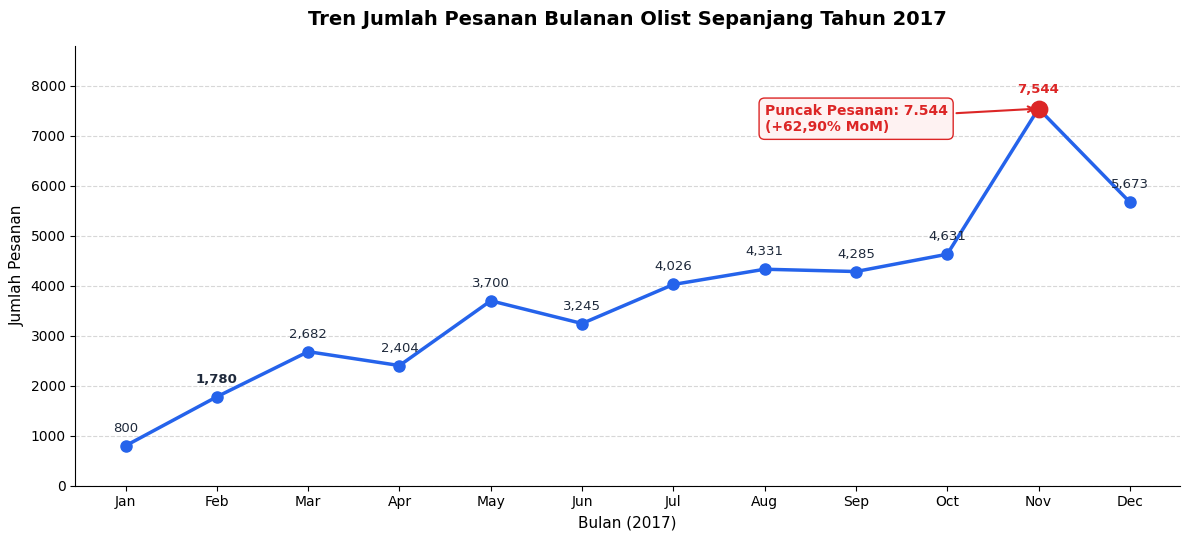

In [20]:
# Membuat visualisasi tren pesanan bulanan sepanjang tahun 2017
fig, ax = plt.subplots(figsize=(12, 5.5))

months_short = monthly_orders_2017["month_name"].str[:3]
ax.plot(months_short, monthly_orders_2017["total_orders"], marker="o", linewidth=2.5, color="#2563EB", markersize=8)

# Menyorot titik puncak pada bulan November
peak_row = monthly_orders_2017.loc[monthly_orders_2017["total_orders"].idxmax()]
ax.scatter([peak_row["month_name"][:3]], [peak_row["total_orders"]], color="#DC2626", s=140, zorder=5)

# Menampilkan angka total pesanan di atas setiap titik bulan
for _, row in monthly_orders_2017.iterrows():
    offset = 280 if row["month_num"] != 11 else 320
    weight = "bold" if row["month_num"] in [2, 11] else "normal"
    color = "#DC2626" if row["month_num"] == 11 else "#1E293B"
    ax.text(
        row["month_name"][:3],
        row["total_orders"] + offset,
        f"{row['total_orders']:,}",
        ha="center",
        fontsize=9.5,
        fontweight=weight,
        color=color
    )

# Menambahkan kotak anotasi pada puncak pesanan
ax.annotate(
    "Puncak Pesanan: 7.544\n(+62,90% MoM)",
    xy=("Nov", 7544),
    xytext=("Aug", 7100),
    arrowprops=dict(arrowstyle="->", color="#DC2626", lw=1.5),
    fontsize=10,
    fontweight="bold",
    color="#DC2626",
    bbox=dict(boxstyle="round,pad=0.4", facecolor="#FEF2F2", edgecolor="#DC2626", lw=1)
)

ax.set_ylim(0, 8800)
ax.set_title("Tren Jumlah Pesanan Bulanan Olist Sepanjang Tahun 2017", fontsize=14, fontweight="bold", pad=15)
ax.set_xlabel("Bulan (2017)", fontsize=11)
ax.set_ylabel("Jumlah Pesanan", fontsize=11)
ax.grid(axis="y", linestyle="--", alpha=0.5)
sns.despine()
plt.tight_layout()
plt.show()

### Pertanyaan 2: Lima kategori produk apa saja yang menyumbang jumlah ulasan negatif terbanyak (skor ulasan 1 dan 2) pada periode Januari–Agustus 2018, dan berapa persentase pesanan yang mengalami keterlambatan pengiriman pada kelima kategori tersebut?

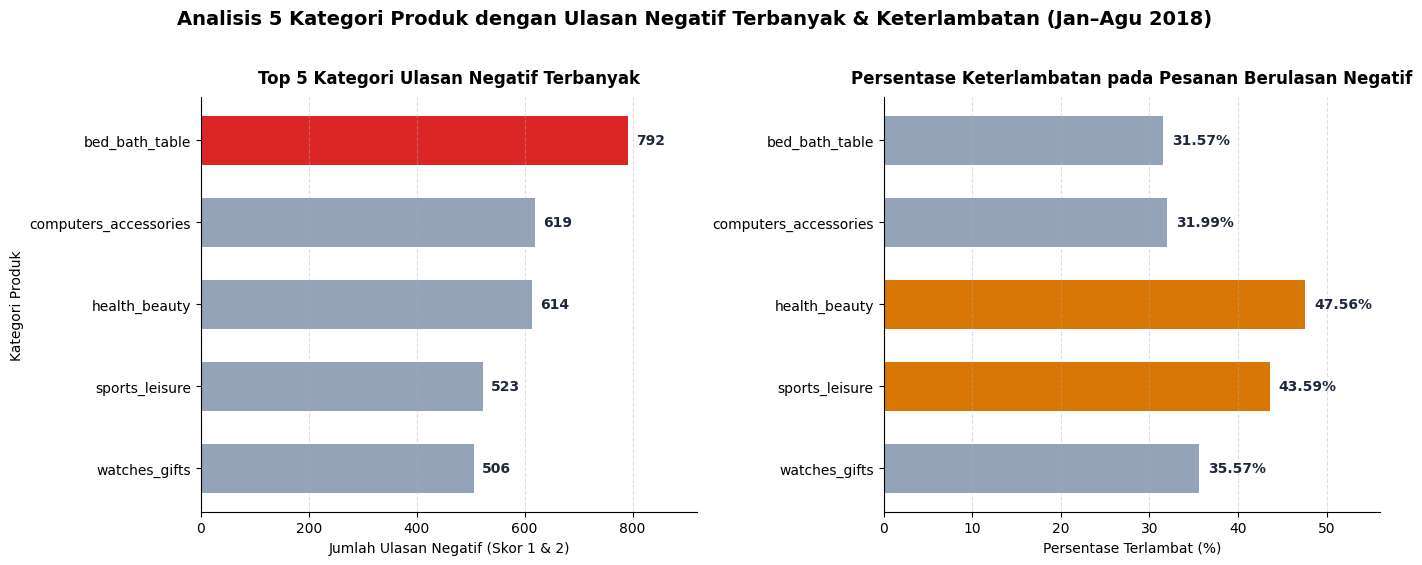

In [21]:
# Membuat visualisasi berdampingan untuk jumlah ulasan negatif & persentase keterlambatan
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Urutkan terbalik agar peringkat #1 berada di posisi paling atas pada grafik horizontal
plot_df = top5_neg_categories.iloc[::-1]

# Panel Kiri: Jumlah Ulasan Negatif
colors_1 = ["#94A3B8", "#94A3B8", "#94A3B8", "#94A3B8", "#DC2626"]
bars1 = axes[0].barh(plot_df["product_category_name_english"], plot_df["jumlah_ulasan_negatif"], color=colors_1, height=0.6)
axes[0].set_title("Top 5 Kategori Ulasan Negatif Terbanyak", fontsize=12, fontweight="bold", pad=10)
axes[0].set_xlabel("Jumlah Ulasan Negatif (Skor 1 & 2)", fontsize=10)
axes[0].set_ylabel("Kategori Produk", fontsize=10)
axes[0].set_xlim(0, 920)
axes[0].grid(axis="x", linestyle="--", alpha=0.4)

for bar in bars1:
    width = bar.get_width()
    axes[0].text(width + 15, bar.get_y() + bar.get_height()/2, f"{int(width)}", va="center", fontsize=10, fontweight="bold", color="#1E293B")

# Panel Kanan: Persentase Keterlambatan Pengiriman
colors_2 = ["#D97706" if pct > 40 else "#94A3B8" for pct in plot_df["persentase_terlambat"]]
bars2 = axes[1].barh(plot_df["product_category_name_english"], plot_df["persentase_terlambat"], color=colors_2, height=0.6)
axes[1].set_title("Persentase Keterlambatan pada Pesanan Berulasan Negatif", fontsize=12, fontweight="bold", pad=10)
axes[1].set_xlabel("Persentase Terlambat (%)", fontsize=10)
axes[1].set_xlim(0, 56)
axes[1].grid(axis="x", linestyle="--", alpha=0.4)

for bar in bars2:
    width = bar.get_width()
    axes[1].text(width + 1, bar.get_y() + bar.get_height()/2, f"{width:.2f}%", va="center", fontsize=10, fontweight="bold", color="#1E293B")

fig.suptitle("Analisis 5 Kategori Produk dengan Ulasan Negatif Terbanyak & Keterlambatan (Jan–Agu 2018)", fontsize=14, fontweight="bold", y=1.02)
sns.despine()
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- **Visualisasi Pertanyaan 1:** Grafik memperlihatkan pertumbuhan volume pemesanan yang konsisten meningkat sepanjang tahun 2017, dimulai dari **800 pesanan** pada Januari hingga mencapai puncaknya pada **November 2017** sebesar **7.544 pesanan** (tumbuh **+62,90% MoM** bertepatan dengan momentum belanja *Black Friday*), sebelum kembali melandai pada Desember menjadi **5.673 pesanan**.
- **Visualisasi Pertanyaan 2:** Perbandingan dua panel menunjukkan bahwa **bed_bath_table** menyumbang ulasan negatif terbanyak (**792 ulasan**) namun memiliki tingkat keterlambatan terendah di antara lima besar (**31,57%**), menandakan keluhan lebih banyak dipicu oleh kualitas atau kesesuaian produk. Sebaliknya, **health_beauty** (**47,56%**) dan **sports_leisure** (**43,59%**) mencatat tingkat keterlambatan tertinggi, sehingga perbaikan kecepatan pengiriman menjadi prioritas utama pada kedua kategori tersebut.

## Analisis Lanjutan (Opsional)

### RFM Analysis (Segmentasi Pelanggan Berdasarkan Recency, Frequency, dan Monetary)
Pada tahap analisis lanjutan ini, dilakukan segmentasi terhadap pelanggan unik (`customer_unique_id`) dari pesanan berstatus *delivered* menggunakan pendekatan **RFM Analysis**:
- **Recency (R):** Jumlah hari sejak transaksi terakhir pelanggan hingga tanggal acuan (1 hari setelah transaksi terakhir dalam dataset). Semakin kecil nilainya, semakin baru pelanggan bertransaksi.
- **Frequency (F):** Total jumlah pesanan unik yang pernah dilakukan oleh pelanggan.
- **Monetary (M):** Total nilai pengeluaran pelanggan (harga produk ditambah ongkos kirim dalam mata uang BRL / R$).

Total pelanggan unik (delivered): 93,350 pelanggan

=== Rangkuman Statistik Metrik RFM ===


,recency,frequency,monetary
count,93350.00,93350.00,93350.00
mean,237.95,1.03,165.17
std,152.59,0.21,226.30
min,1.00,1.00,9.59
25%,114.00,1.00,63.01
50%,219.00,1.00,107.78
75%,346.00,1.00,182.50
max,714.00,15.00,13664.08



=== Ringkasan Segmen Pelanggan (RFM) ===


,segment,jumlah_pelanggan,rata_rata_recency,rata_rata_frequency,rata_rata_monetary,persentase_pelanggan
3,Need Attention,38438,265.33,1.00,129.38,41.18
2,Loyal Customers,31485,175.33,1.04,215.15,33.73
0,At Risk / Lost,15436,372.66,1.00,65.01,16.54
1,Champions,7991,92.74,1.20,333.86,8.56


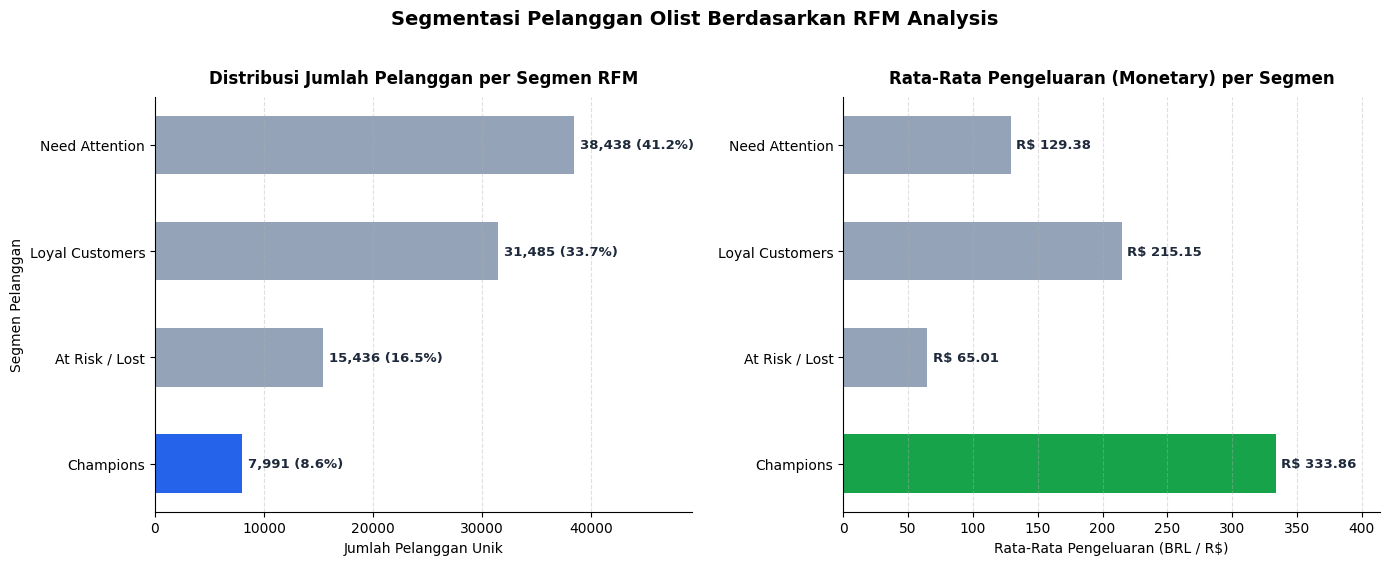

In [23]:
# Memuat data pelanggan dari folder data/ untuk mendapatkan customer_unique_id
customers_df = pd.read_csv("data/customers_dataset.csv")

# Menghitung nilai transaksi per pesanan (harga produk + ongkos kirim) dari items_df
items_df["total_item_value"] = items_df["price"] + items_df["freight_value"]
order_monetary = items_df.groupby("order_id", as_index=False)["total_item_value"].sum()

# Menggabungkan pesanan berstatus 'delivered' dengan customer_unique_id dan nilai pesanan
rfm_orders = (
    delivered_orders_df[["order_id", "customer_id", "order_purchase_timestamp"]]
    .merge(customers_df[["customer_id", "customer_unique_id"]], on="customer_id", how="inner")
    .merge(order_monetary, on="order_id", how="inner")
)

# Menentukan tanggal acuan (1 hari setelah tanggal transaksi terakhir pada dataset)
recent_date = rfm_orders["order_purchase_timestamp"].max() + pd.Timedelta(days=1)

# Menghitung metrik Recency, Frequency, dan Monetary untuk setiap pelanggan unik
rfm_df = rfm_orders.groupby("customer_unique_id", as_index=False).agg(
    max_order_timestamp=("order_purchase_timestamp", "max"),
    frequency=("order_id", "nunique"),
    monetary=("total_item_value", "sum")
)
rfm_df["recency"] = (recent_date - rfm_df["max_order_timestamp"]).dt.days
rfm_df.drop(columns=["max_order_timestamp"], inplace=True)

# Memberikan skor 1-5 untuk R, F, M menggunakan kuantil dan menentukan segmen pelanggan
rfm_df["r_score"] = pd.qcut(rfm_df["recency"].rank(method="first"), q=5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm_df["f_score"] = pd.qcut(rfm_df["frequency"].rank(method="first"), q=5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm_df["m_score"] = pd.qcut(rfm_df["monetary"].rank(method="first"), q=5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm_df["rfm_score"] = rfm_df["r_score"] + rfm_df["f_score"] + rfm_df["m_score"]

def assign_rfm_segment(score):
    if score >= 13:
        return "Champions"
    elif score >= 10:
        return "Loyal Customers"
    elif score >= 7:
        return "Need Attention"
    else:
        return "At Risk / Lost"

rfm_df["segment"] = rfm_df["rfm_score"].apply(assign_rfm_segment)

# Menampilkan ringkasan statistik RFM dan rekapitulasi per segmen
print(f"Total pelanggan unik (delivered): {len(rfm_df):,} pelanggan")
print("\n=== Rangkuman Statistik Metrik RFM ===")
display(rfm_df[["recency", "frequency", "monetary"]].describe().round(2))

segment_summary = (
    rfm_df.groupby("segment", as_index=False)
    .agg(
        jumlah_pelanggan=("customer_unique_id", "count"),
        rata_rata_recency=("recency", "mean"),
        rata_rata_frequency=("frequency", "mean"),
        rata_rata_monetary=("monetary", "mean")
    )
    .sort_values("jumlah_pelanggan", ascending=False)
)
segment_summary["persentase_pelanggan"] = (segment_summary["jumlah_pelanggan"] / len(rfm_df) * 100).round(2)
segment_summary[["rata_rata_recency", "rata_rata_frequency", "rata_rata_monetary"]] = segment_summary[
    ["rata_rata_recency", "rata_rata_frequency", "rata_rata_monetary"]
].round(2)

print("\n=== Ringkasan Segmen Pelanggan (RFM) ===")
display(segment_summary)

# Visualisasi Distribusi Segmen Pelanggan & Rata-Rata Nilai Belanja (Monetary) per Segmen
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

plot_seg = segment_summary.iloc[::-1]

# Panel Kiri: Jumlah Pelanggan per Segmen
colors_seg = ["#94A3B8" if seg != "Champions" else "#2563EB" for seg in plot_seg["segment"]]
bars1 = axes[0].barh(plot_seg["segment"], plot_seg["jumlah_pelanggan"], color=colors_seg, height=0.55)
axes[0].set_title("Distribusi Jumlah Pelanggan per Segmen RFM", fontsize=12, fontweight="bold", pad=10)
axes[0].set_xlabel("Jumlah Pelanggan Unik", fontsize=10)
axes[0].set_ylabel("Segmen Pelanggan", fontsize=10)
axes[0].set_xlim(0, plot_seg["jumlah_pelanggan"].max() * 1.28)
axes[0].grid(axis="x", linestyle="--", alpha=0.4)

for bar, pct in zip(bars1, plot_seg["persentase_pelanggan"]):
    width = bar.get_width()
    axes[0].text(
        width + 500,
        bar.get_y() + bar.get_height() / 2,
        f"{int(width):,} ({pct:.1f}%)",
        va="center",
        fontsize=9.5,
        fontweight="bold",
        color="#1E293B"
    )

# Panel Kanan: Rata-Rata Pengeluaran (Monetary) per Segmen
colors_mon = ["#16A34A" if seg == "Champions" else "#94A3B8" for seg in plot_seg["segment"]]
bars2 = axes[1].barh(plot_seg["segment"], plot_seg["rata_rata_monetary"], color=colors_mon, height=0.55)
axes[1].set_title("Rata-Rata Pengeluaran (Monetary) per Segmen", fontsize=12, fontweight="bold", pad=10)
axes[1].set_xlabel("Rata-Rata Pengeluaran (BRL / R$)", fontsize=10)
axes[1].set_xlim(0, plot_seg["rata_rata_monetary"].max() * 1.24)
axes[1].grid(axis="x", linestyle="--", alpha=0.4)

for bar in bars2:
    width = bar.get_width()
    axes[1].text(
        width + 4,
        bar.get_y() + bar.get_height() / 2,
        f"R$ {width:,.2f}",
        va="center",
        fontsize=9.5,
        fontweight="bold",
        color="#1E293B"
    )

fig.suptitle("Segmentasi Pelanggan Olist Berdasarkan RFM Analysis", fontsize=14, fontweight="bold", y=1.02)
sns.despine()
plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Dari total **93.350 pelanggan unik** (pesanan berstatus *delivered*), mayoritas pelanggan hanya melakukan transaksi sebanyak **1 kali** (nilai kuartil hingga persentil ke-75 berada pada angka `1.00`, dengan rata-rata frekuensi `1.03`), yang menunjukkan bahwa basis pelanggan Olist masih didominasi oleh pembeli satu kali (*one-time buyers*).
- Segmen **Champions** hanya mencakup **8,56%** (**7.991 pelanggan**), namun menyumbang rata-rata nilai belanja (*Monetary*) tertinggi sebesar **R$ 333,86** dengan jeda transaksi terakhir (*Recency*) paling singkat (**92,74 hari**) dan rata-rata frekuensi tertinggi (**1,20 transaksi**).
- Sebaliknya, lebih dari separuh pelanggan berada pada segmen **Need Attention** (**41,18%** atau **38.438 pelanggan**; rata-rata *recency* **265,33 hari**) dan **At Risk / Lost** (**16,54%** atau **15.436 pelanggan**; rata-rata *recency* **372,66 hari**), sehingga membutuhkan strategi reaktivasi agar tidak berhenti bertransaksi sepenuhnya.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Sepanjang tahun 2017, platform Olist mencatatkan total **45.101 pesanan** dengan tren pertumbuhan yang konsisten menanjak (rata-rata **3.758,42 pesanan/bulan**). Pertumbuhan persentase (*Month-over-Month*) tertinggi terjadi pada **Februari 2017** sebesar **+122,50%** (naik dari 800 pesanan di Januari menjadi 1.780 pesanan), sedangkan lonjakan volume pesanan tertinggi terjadi pada **November 2017** yang mencapai puncak **7.544 pesanan** (tumbuh **+62,90% MoM** dari Oktober sebesar 4.631 pesanan) seiring momentum belanja akhir tahun (*Black Friday*), sebelum melandai sebesar **-24,80%** pada Desember menjadi 5.673 pesanan.
- **Conclusion pertanyaan 2:** Pada periode Januari–Agustus 2018 (pesanan berstatus *delivered*), lima kategori produk penyumbang ulasan negatif (skor 1 dan 2) terbanyak adalah **bed_bath_table** (**792 ulasan**; keterlambatan **31,57%**), **computers_accessories** (**619 ulasan**; keterlambatan **31,99%**), **health_beauty** (**614 ulasan**; keterlambatan **47,56%**), **sports_leisure** (**523 ulasan**; keterlambatan **43,59%**), dan **watches_gifts** (**506 ulasan**; keterlambatan **35,57%**), yang secara keseluruhan menyumbang **42,33%** (3.054 dari 7.214 ulasan) dari total ulasan negatif platform. Temuan ini menunjukkan dua akar masalah berbeda: keluhan pada **health_beauty** dan **sports_leisure** didominasi keterlambatan pengiriman (>43%), sedangkan hampir 70% pesanan berulasan negatif pada **bed_bath_table** dan **computers_accessories** sebenarnya tiba tepat waktu sehingga lebih dipicu faktor kualitas atau kesesuaian produk.
- **Conclusion Analisis Lanjutan (RFM Analysis):** Dari **93.350 pelanggan unik** (*delivered*), basis pelanggan masih didominasi pembeli satu kali (*one-time buyers*, rata-rata frekuensi **1,03 transaksi**). Segmen **Champions** (**8,56%** atau **7.991 pelanggan**) memberikan rata-rata pengeluaran (*Monetary*) tertinggi sebesar **R$ 333,86** dengan jeda transaksi tersingkat (**92,74 hari**), sedangkan **57,72%** pelanggan berada pada segmen **Need Attention** (**41,18%**) dan **At Risk / Lost** (**16,54%**) dengan jeda transaksi terakhir lebih dari 265 hari.


**Rekomendasi Action Item:**

- **Antisipasi Lonjakan Musiman Kuartal IV:** Tim operasional dan logistik perlu meningkatkan kapasitas inventaris, kesiapan *seller*, serta kuota armada pengiriman mulai awal Oktober hingga November untuk mengantisipasi lonjakan pesanan hingga hampir dua kali lipat, sekaligus menyiapkan promo retensi pasca-November guna menjaga volume transaksi di bulan Desember.
- **Perbaikan SLA Pengiriman pada Kategori Sensitif Waktu:** Melakukan evaluasi kinerja mitra kurir serta mempercepat proses *handover* gudang khusus pada kategori **health_beauty** (keterlambatan 47,56%) dan **sports_leisure** (keterlambatan 43,59%) agar tingkat keterlambatan turun signifikan.
- **Audit Kualitas & Pengemasan Produk:** Memperketat standar kurasi produk, kelengkapan deskripsi spesifikasi, serta keamanan pengemasan (*packaging*) dari *seller* pada kategori **bed_bath_table** dan **computers_accessories** untuk menekan ulasan negatif yang berasal dari ketidaksesuaian atau kerusakan barang.
- **Program Loyalitas & Kampanye Reaktivasi Pelanggan:** Memberikan program *reward* eksklusif untuk mempertahankan segmen **Champions** (**8,56%**) dan **Loyal Customers** (**33,73%**), serta meluncurkan kampanye *re-engagement* berbasis voucher diskon pembelian kedua bagi segmen **Need Attention** dan **At Risk / Lost** guna meningkatkan *repeat order*.

## Export Dataset Utama untuk Aplikasi Dashboard
Seluruh entitas data yang sudah melalui tahap pembersihan dan transformasi (`orders_df`, `customers_df`, `items_df`, `reviews_df`, serta `products_translated`) dikonsolidasikan ke dalam satu berkas CSV terpadu bernama `main_data.csv` sebagai sumber data utama bagi antarmuka visualisasi interaktif pada Streamlit.

In [ ]:
# Menghitung total nilai pembayaran per transaksi (harga barang + ongkos kirim)
items_df["total_item_value"] = items_df["price"] + items_df["freight_value"]
order_total_df = items_df.groupby("order_id", as_index=False)["total_item_value"].sum().rename(
    columns={"total_item_value": "total_order_value"}
)

# Memetakan kategori produk berbahasa Inggris pada setiap pesanan tanpa duplikasi kategori
order_category_df = (
    items_df[["order_id", "product_id"]]
    .merge(products_translated[["product_id", "product_category_name_english"]], on="product_id", how="left")
    .drop_duplicates(subset=["order_id", "product_category_name_english"])
    [["order_id", "product_category_name_english"]]
)

# Menyusun tabel terpadu untuk kebutuhan visualisasi interaktif
dashboard_dataset = (
    orders_df[[
        "order_id",
        "customer_id",
        "order_status",
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]]
    .merge(customers_df[["customer_id", "customer_unique_id"]], on="customer_id", how="left")
    .merge(order_total_df, on="order_id", how="left")
    .merge(reviews_df[["order_id", "review_id", "review_score"]], on="order_id", how="left")
    .merge(order_category_df, on="order_id", how="left")
)

# Menambahkan indikator biner status keterlambatan pengiriman
dashboard_dataset["is_late"] = (
    (dashboard_dataset["order_status"] == "delivered") &
    (dashboard_dataset["order_delivered_customer_date"].notna()) &
    (dashboard_dataset["order_delivered_customer_date"] > dashboard_dataset["order_estimated_delivery_date"])
)

# Memilih atribut relevan sebelum diekspor menjadi berkas CSV
selected_columns = [
    "order_id",
    "customer_unique_id",
    "order_status",
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "is_late",
    "review_id",
    "review_score",
    "product_category_name_english",
    "total_order_value"
]

dashboard_dataset[selected_columns].to_csv("main_data.csv", index=False)
print(f"File main_data.csv selesai diekspor dengan total {len(dashboard_dataset):,} baris.")

File main_data.csv selesai diekspor dengan total 100,806 baris.
